## 1. Setup

In [ ]:
import os, re, time, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42          # seed yang sama untuk SEMUA kelompok agar split data identik
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

## 2. Dataset

Jumlah data  : 243
Jumlah intent: 13


,pertanyaan,intent
24,bye bye,perpisahan
6,selamat malam,salam
152,bagaimana mengisi krs online,krs
232,cara membuat kopi susu,di_luar_topik
238,berapa hasil 25 dikali 4,di_luar_topik
175,gimana cara masuk jaringan hotspot kampus,wifi
215,dari terminal ke kampus naik apa,lokasi_kampus
150,kelas hari ini jam berapa,jadwal_kuliah


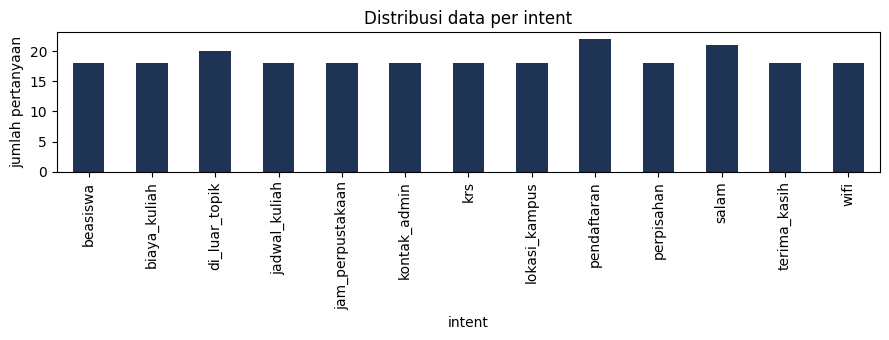

In [ ]:
FILE = "dataset_chatbot.xlsx"

if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Unggah file", FILE)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

df = pd.read_excel(FILE)            # kolom: pertanyaan, intent, jawaban
RESPONS = df.groupby("intent")["jawaban"].first().to_dict()
CLASSES = sorted(df["intent"].unique())

print("Jumlah data  :", len(df))
print("Jumlah intent:", len(CLASSES))
display(df[["pertanyaan", "intent"]].sample(8, random_state=SEED))

ax = df["intent"].value_counts().sort_index().plot(kind="bar", figsize=(9, 3.5), color="#1f3354")
ax.set_title("Distribusi data per intent")
ax.set_ylabel("jumlah pertanyaan")
plt.tight_layout()
plt.show()

## 3. Preprocessing dasar (sama untuk kedua model)

Langkah: huruf kecil, hapus tanda baca, normalisasi kata tidak baku, dan buang kata pengisi (kak, dong, ya, ...).

In [ ]:
NORMALISASI = {
    "gak": "tidak", "ga": "tidak", "gk": "tidak", "nggak": "tidak", "ngga": "tidak",
    "udah": "sudah", "yaudah": "ya sudah", "aja": "saja", "gimana": "bagaimana", "bgmn": "bagaimana",
    "brp": "berapa", "bgt": "banget", "yg": "yang", "dgn": "dengan", "sy": "saya", "gue": "saya",
    "makasih": "terima kasih", "trims": "terima kasih", "thanks": "terima kasih", "thx": "terima kasih",
    "tengkyu": "terima kasih", "perpus": "perpustakaan", "wa": "whatsapp", "hallo": "halo", "hai": "halo", "haloo": "halo", "halooo": "halo"
}
KATA_PENGISI = {"kak", "dong", "ya", "nih", "deh", "sih", "kok", "yah", "pak", "bu"}

def preprocess(teks):
    teks = str(teks).lower()
    teks = re.sub(r"[^a-z0-9\s]", " ", teks)
    teks = re.sub(r"\s+", " ", teks).strip()
    hasil = []
    for kata in teks.split():
        kata = NORMALISASI.get(kata, kata)
        hasil.extend(k for k in kata.split() if k not in KATA_PENGISI)
    return " ".join(hasil)

for contoh in ["Gimana caranya daftar kuliah, kak??", "makasih bgt ya kak infonya!", "Perpus buka jam brp?"]:
    print(f"{contoh!r:45} -> {preprocess(contoh)!r}")

df["bersih"] = df["pertanyaan"].apply(preprocess)

'Gimana caranya daftar kuliah, kak??'         -> 'bagaimana caranya daftar kuliah'
'makasih bgt ya kak infonya!'                 -> 'terima kasih banget infonya'
'Perpus buka jam brp?'                        -> 'perpustakaan buka jam berapa'


## 4. Split data (sama untuk semua kelompok)

Stratified 70% latih, 15% validasi, 15% uji dengan `random_state=42`.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["intent"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["intent"], random_state=SEED)

print(f"Train: {len(train_df)} | Validasi: {len(val_df)} | Uji: {len(test_df)}")

Train: 170 | Validasi: 36 | Uji: 37


## 5. Model 1: Chatbot Retrieval (TF-IDF + Cosine Similarity)


In [ ]:
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_train_m1 = tfidf.fit_transform(train_df["bersih"])
y_train_labels = train_df["intent"].values
train_time_m1 = time.time() - t0

def predict_m1(texts):
    # kembalikan (daftar intent, daftar skor kemiripan)
    bersih = [preprocess(t) for t in texts]
    sims = cosine_similarity(tfidf.transform(bersih), X_train_m1)
    idx = sims.argmax(axis=1)
    return list(y_train_labels[idx]), list(sims.max(axis=1))

print(f"Ukuran vocabulary TF-IDF: {len(tfidf.vocabulary_)}")
print(f"Waktu training Model 1  : {train_time_m1:.4f} detik")

Ukuran vocabulary TF-IDF: 802
Waktu training Model 1  : 0.0230 detik


## 6. Model 2: Chatbot Neural Network (Tokenisasi → Padding → Embedding → GRU/LSTM)

Ganti `RNN_TYPE` ke `"LSTM"` bila ingin membandingkan GRU dan LSTM.

In [ ]:
import tensorflow as tf
tf.random.set_seed(SEED)

# --- Tokenisasi: bangun kamus kata dari data latih saja ---
vocab = sorted({tok for s in train_df["bersih"] for tok in s.split()})
word_index = {"<PAD>": 0, "<OOV>": 1}
for w in vocab:
    word_index[w] = len(word_index)
VOCAB_SIZE = len(word_index)

def texts_to_sequences(texts):
    return [[word_index.get(tok, 1) for tok in s.split()] for s in texts]

# --- Padding: samakan panjang input ---
MAXLEN = 30
def pad(seqs, maxlen=MAXLEN):
    arr = np.zeros((len(seqs), maxlen), dtype="int32")
    for i, s in enumerate(seqs):
        s = s[:maxlen]
        arr[i, :len(s)] = s
    return arr

def encode(texts_bersih):
    return pad(texts_to_sequences(texts_bersih))

label2id = {c: i for i, c in enumerate(CLASSES)}
X_train, y_train = encode(train_df["bersih"]), train_df["intent"].map(label2id).values
X_val, y_val = encode(val_df["bersih"]), val_df["intent"].map(label2id).values

contoh = train_df["bersih"].iloc[0]
print("Teks bersih :", contoh)
print("Token ID    :", texts_to_sequences([contoh])[0])
print("Setelah pad :", pad(texts_to_sequences([contoh]))[0])
print("Vocab size  :", VOCAB_SIZE)

Teks bersih : ada keringanan biaya kuliah tidak
Token ID    : [4, 138, 41, 149, 297]
Setelah pad : [  4 138  41 149 297   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0]
Vocab size  : 316


In [ ]:
RNN_TYPE = "GRU"     # ganti "LSTM" untuk membandingkan
rnn_layer = tf.keras.layers.GRU if RNN_TYPE == "GRU" else tf.keras.layers.LSTM

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAXLEN,)),
    tf.keras.layers.Embedding(VOCAB_SIZE, 64, mask_zero=True),
    tf.keras.layers.Bidirectional(rnn_layer(64)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(len(CLASSES), activation="softmax"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

t0 = time.time()
history_m2 = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=200, batch_size=16, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)],
)
train_time_m2 = time.time() - t0
print(f"Epoch yang dijalankan : {len(history_m2.history['loss'])}")
print(f"Waktu training Model 2: {train_time_m2:.2f} detik")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,245 (309.55 KB)

 Trainable params: 79,245 (309.55 KB)

 Non-trainable params: 0 (0.00 B)

Epoch yang dijalankan : 33
Waktu training Model 2: 22.64 detik


In [ ]:
def predict_m2(texts):
    probs = model.predict(encode([preprocess(t) for t in texts]), verbose=0)
    return [CLASSES[i] for i in probs.argmax(axis=1)], list(probs.max(axis=1))

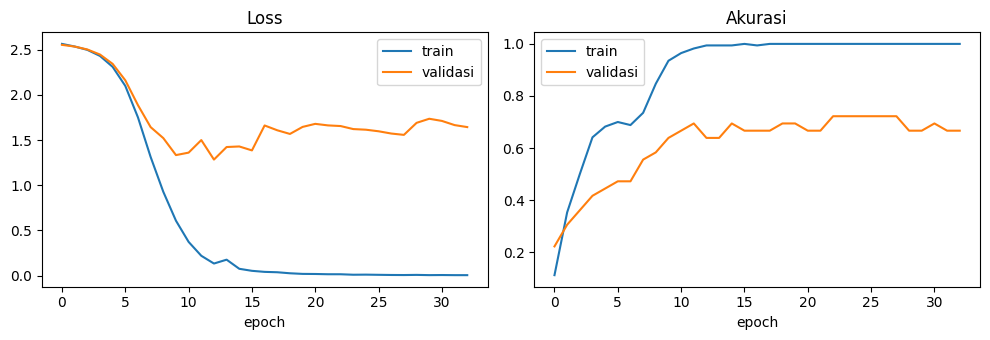

In [ ]:
h = history_m2.history
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validasi")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(h["accuracy"], label="train"); axes[1].plot(h["val_accuracy"], label="validasi")
axes[1].set_title("Akurasi"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Evaluasi pada data uji (metrik sama: akurasi dan F1-score macro)

In [ ]:
test_texts = test_df["pertanyaan"].tolist()
y_test = test_df["intent"].tolist()

t0 = time.time(); pred1, skor1 = predict_m1(test_texts); infer_m1 = (time.time() - t0) / len(test_texts)
t0 = time.time(); pred2, skor2 = predict_m2(test_texts); infer_m2 = (time.time() - t0) / len(test_texts)

def ringkas(nama, y_true, y_pred):
    return {"Model": nama,
            "Akurasi": accuracy_score(y_true, y_pred),
            "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0)}

tabel_test = pd.DataFrame([ringkas("Model 1: TF-IDF retrieval", y_test, pred1),
                           ringkas(f"Model 2: Bi-{RNN_TYPE}", y_test, pred2)]).round(4)
display(tabel_test)

print("=== Laporan klasifikasi Model 1 ===")
print(classification_report(y_test, pred1, zero_division=0))
print("=== Laporan klasifikasi Model 2 ===")
print(classification_report(y_test, pred2, zero_division=0))

,Model,Akurasi,F1 macro
0,Model 1: TF-IDF retrieval,0.5676,0.5377
1,Model 2: Bi-GRU,0.8649,0.8484


=== Laporan klasifikasi Model 1 ===
                  precision    recall  f1-score   support

        beasiswa       0.00      0.00      0.00         2
    biaya_kuliah       1.00      0.50      0.67         2
   di_luar_topik       1.00      0.33      0.50         3
   jadwal_kuliah       0.50      1.00      0.67         3
jam_perpustakaan       1.00      0.67      0.80         3
    kontak_admin       0.67      0.67      0.67         3
             krs       0.25      0.50      0.33         2
   lokasi_kampus       0.00      0.00      0.00         3
     pendaftaran       0.50      0.50      0.50         4
      perpisahan       0.67      0.67      0.67         3
           salam       0.67      0.67      0.67         3
    terima_kasih       0.75      1.00      0.86         3
            wifi       0.67      0.67      0.67         3

        accuracy                           0.57        37
       macro avg       0.59      0.55      0.54        37
    weighted avg       0.60      0

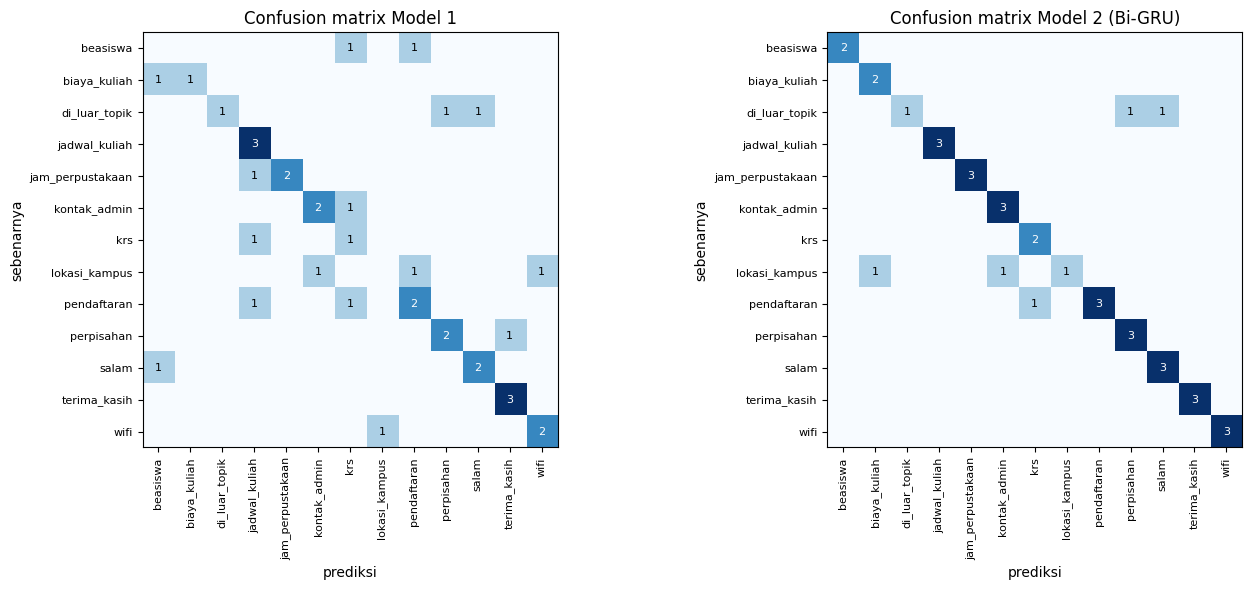

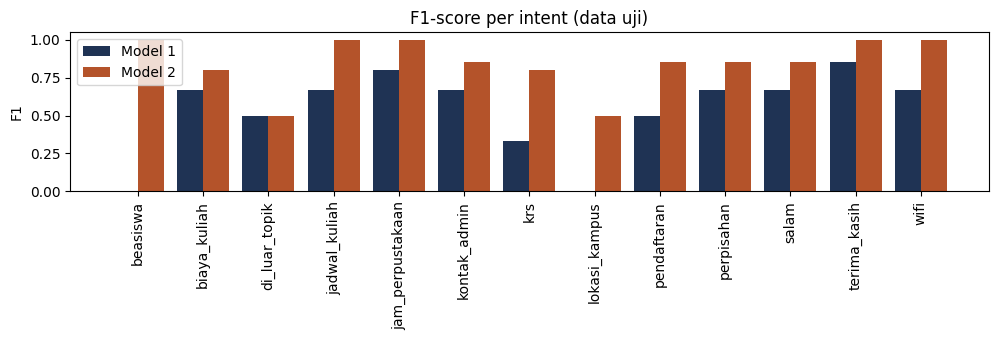

In [ ]:
def plot_cm(ax, y_true, y_pred, judul):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=8)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=8)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(judul); ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_cm(axes[0], y_test, pred1, "Confusion matrix Model 1")
plot_cm(axes[1], y_test, pred2, f"Confusion matrix Model 2 (Bi-{RNN_TYPE})")
plt.tight_layout()
plt.show()

f1_m1 = f1_score(y_test, pred1, labels=CLASSES, average=None, zero_division=0)
f1_m2 = f1_score(y_test, pred2, labels=CLASSES, average=None, zero_division=0)
x = np.arange(len(CLASSES))
plt.figure(figsize=(10, 3.5))
plt.bar(x - 0.2, f1_m1, 0.4, label="Model 1", color="#1f3354")
plt.bar(x + 0.2, f1_m2, 0.4, label="Model 2", color="#b4532a")
plt.xticks(x, CLASSES, rotation=90); plt.ylabel("F1"); plt.title("F1-score per intent (data uji)")
plt.legend(); plt.tight_layout(); plt.show()

## 8. Uji kalimat bervariasi dan kalimat panjang

Data uji di atas berasal dari gaya kalimat yang mirip data latih. Di sini kedua model diuji dengan 26 kalimat baru yang ditulis berbeda: kalimat panjang (10 kata atau lebih), singkatan, dan susunan yang tidak ada di data latih. Silakan tambahkan kalimat uji milik kelompok Anda.

In [ ]:
UJI_VARIASI = [
    ("selamat pagi pak, maaf mengganggu waktunya, saya mau konsultasi sebentar", "salam"),
    ("halooo admin", "salam"),
    ("baik kalau sudah jelas semua, saya mau lanjut kegiatan lain, sampai bertemu kembali", "perpisahan"),
    ("dah bot", "perpisahan"),
    ("terima kasih banyak ya atas penjelasannya yang sangat lengkap dan mudah dipahami", "terima_kasih"),
    ("makasih bgt kak", "terima_kasih"),
    ("kalau saya mau ke perpustakaan sore hari sepulang kuliah apakah masih buka?", "jam_perpustakaan"),
    ("perpus tutup jam brp", "jam_perpustakaan"),
    ("saya baru lulus SMK dan ingin kuliah di sini, apa saja yang harus saya lakukan untuk mendaftar?", "pendaftaran"),
    ("syarat masuk apa aja ya", "pendaftaran"),
    ("tolong jelaskan berapa besar dana yang harus saya bayarkan setiap semester untuk jurusan teknik informatika", "biaya_kuliah"),
    ("ukt brp", "biaya_kuliah"),
    ("adik saya mau kuliah tapi orang tua tidak mampu, apakah ada program bantuan dari kampus?", "beasiswa"),
    ("ada beasiswa gak sih", "beasiswa"),
    ("bagaimana caranya supaya saya bisa tahu hari dan jam kuliah untuk setiap mata kuliah yang saya ambil?", "jadwal_kuliah"),
    ("jadwal uts kapan", "jadwal_kuliah"),
    ("saya mau menambah satu mata kuliah lagi setelah krs saya disetujui, apakah masih bisa diubah?", "krs"),
    ("krs nya gimana sih", "krs"),
    ("laptop saya tidak bisa terhubung ke internet kampus padahal sudah memasukkan akun yang benar", "wifi"),
    ("wifi kampus error", "wifi"),
    ("saya perlu menyampaikan masalah pembayaran, siapa yang bisa saya hubungi dan lewat apa?", "kontak_admin"),
    ("no wa admin", "kontak_admin"),
    ("saya belum pernah ke kampus ini, bisa tolong tunjukkan arah dan alamat lengkapnya?", "lokasi_kampus"),
    ("kampus di mana sih", "lokasi_kampus"),
    ("saya penasaran, kira-kira besok hujan atau tidak di daerah sini ya", "di_luar_topik"),
    ("tolong carikan resep nasi goreng", "di_luar_topik"),
]

var_df = pd.DataFrame(UJI_VARIASI, columns=["kalimat", "intent"])
var_df["jumlah_kata"] = var_df["kalimat"].str.split().str.len()
var_df["kategori"] = np.where(var_df["jumlah_kata"] >= 10, "panjang", "pendek")

var_df["pred_m1"], var_df["skor_m1"] = predict_m1(var_df["kalimat"].tolist())
var_df["pred_m2"], var_df["skor_m2"] = predict_m2(var_df["kalimat"].tolist())
var_df["benar_m1"] = var_df["pred_m1"] == var_df["intent"]
var_df["benar_m2"] = var_df["pred_m2"] == var_df["intent"]

akurasi_var = var_df[["benar_m1", "benar_m2"]].mean().round(4)
akurasi_kategori = var_df.groupby("kategori")[["benar_m1", "benar_m2"]].mean().round(4)
print("Akurasi seluruh kalimat bervariasi:")
display(akurasi_var)
print("Akurasi menurut panjang kalimat:")
display(akurasi_kategori)

Akurasi seluruh kalimat bervariasi:


,0
benar_m1,0.7692
benar_m2,0.7308


Akurasi menurut panjang kalimat:


,benar_m1,benar_m2
kategori,,
panjang,0.6923,0.4615
pendek,0.8462,1.0000


## 9. Contoh prediksi benar dan salah

In [ ]:
test_hasil = pd.DataFrame({"kalimat": test_texts, "intent": y_test, "pred_m1": pred1, "pred_m2": pred2})
test_hasil["benar_m1"] = test_hasil["intent"] == test_hasil["pred_m1"]
test_hasil["benar_m2"] = test_hasil["intent"] == test_hasil["pred_m2"]
test_hasil["sumber"] = "data uji"
var_hasil = var_df[["kalimat", "intent", "pred_m1", "pred_m2", "benar_m1", "benar_m2"]].copy()
var_hasil["sumber"] = "kalimat bervariasi"
semua = pd.concat([test_hasil, var_hasil], ignore_index=True)

kolom = ["sumber", "kalimat", "intent", "pred_m1", "pred_m2"]
print("Kedua model benar (5 contoh):")
display(semua[semua.benar_m1 & semua.benar_m2][kolom].head(5))
print("Model 1 salah, Model 2 benar:")
display(semua[~semua.benar_m1 & semua.benar_m2][kolom].head(5))
print("Model 1 benar, Model 2 salah:")
display(semua[semua.benar_m1 & ~semua.benar_m2][kolom].head(5))
print("Kedua model salah:")
display(semua[~semua.benar_m1 & ~semua.benar_m2][kolom].head(5))

Kedua model benar (5 contoh):


,sumber,kalimat,intent,pred_m1,pred_m2
0,data uji,sampai nanti ya,perpisahan,perpisahan,perpisahan
1,data uji,bisa dicicil gak bayar kuliahnya,biaya_kuliah,biaya_kuliah,biaya_kuliah
3,data uji,hai kak,salam,salam,salam
4,data uji,oke makasih kak,terima_kasih,terima_kasih,terima_kasih
7,data uji,bagian tata usaha bisa dihubungi dimana,kontak_admin,kontak_admin,kontak_admin


Model 1 salah, Model 2 benar:


,sumber,kalimat,intent,pred_m1,pred_m2
2,data uji,cara pakai wifi kampus di hp,wifi,lokasi_kampus,wifi
6,data uji,"saya lulusan SMA tahun ini, bagaimana prosedur mendaftar",pendaftaran,jadwal_kuliah,pendaftaran
10,data uji,kampus ada di kota apa,lokasi_kampus,kontak_admin,lokasi_kampus
18,data uji,berapa biaya kuliah,biaya_kuliah,beasiswa,biaya_kuliah
20,data uji,email dosen pembimbing dimana carinya,kontak_admin,krs,kontak_admin


Model 1 benar, Model 2 salah:


,sumber,kalimat,intent,pred_m1,pred_m2
39,kalimat bervariasi,"baik kalau sudah jelas semua, saya mau lanjut kegiatan lain, sampai bertemu kembali",perpisahan,perpisahan,krs
41,kalimat bervariasi,terima kasih banyak ya atas penjelasannya yang sangat lengkap dan mudah dipahami,terima_kasih,terima_kasih,krs
55,kalimat bervariasi,laptop saya tidak bisa terhubung ke internet kampus padahal sudah memasukkan akun yang benar,wifi,wifi,jadwal_kuliah
57,kalimat bervariasi,"saya perlu menyampaikan masalah pembayaran, siapa yang bisa saya hubungi dan lewat apa?",kontak_admin,kontak_admin,biaya_kuliah


Kedua model salah:


,sumber,kalimat,intent,pred_m1,pred_m2
5,data uji,ada angkot yang lewat kampus gak,lokasi_kampus,wifi,biaya_kuliah
13,data uji,boleh minta link google maps kampus,lokasi_kampus,pendaftaran,kontak_admin
17,data uji,pendaftaran online lewat mana,pendaftaran,krs,krs
30,data uji,siapa juara liga inggris,di_luar_topik,salam,salam
32,data uji,film bagus apa yang lagi tayang,di_luar_topik,perpisahan,perpisahan


## 10. Analisis error

In [ ]:
for nama, kol in [("Model 1", "pred_m1"), ("Model 2", "pred_m2")]:
    salah = semua[semua["intent"] != semua[kol]]
    print(f"=== {nama}: {len(salah)} kalimat salah dari {len(semua)} ===")
    if len(salah):
        pola = (salah["intent"] + "  ->  " + salah[kol]).value_counts().head(8)
        print("Pola kesalahan terbanyak (asli -> prediksi):")
        print(pola.to_string())
        panjang = salah["kalimat"].str.split().str.len()
        print(f"Rata-rata panjang kalimat yang salah: {panjang.mean():.1f} kata "
              f"(semua kalimat: {semua['kalimat'].str.split().str.len().mean():.1f} kata)")
    print()

=== Model 1: 22 kalimat salah dari 63 ===
Pola kesalahan terbanyak (asli -> prediksi):
wifi  ->  lokasi_kampus            1
lokasi_kampus  ->  wifi            1
pendaftaran  ->  jadwal_kuliah     1
lokasi_kampus  ->  kontak_admin    1
lokasi_kampus  ->  pendaftaran     1
pendaftaran  ->  krs               1
biaya_kuliah  ->  beasiswa         1
kontak_admin  ->  krs              1
Rata-rata panjang kalimat yang salah: 6.5 kata (semua kalimat: 6.1 kata)

=== Model 2: 12 kalimat salah dari 63 ===
Pola kesalahan terbanyak (asli -> prediksi):
lokasi_kampus  ->  biaya_kuliah    1
lokasi_kampus  ->  kontak_admin    1
pendaftaran  ->  krs               1
di_luar_topik  ->  salam           1
di_luar_topik  ->  perpisahan      1
perpisahan  ->  krs                1
terima_kasih  ->  krs              1
pendaftaran  ->  kontak_admin      1
Rata-rata panjang kalimat yang salah: 9.9 kata (semua kalimat: 6.1 kata)



## 11. Ringkasan perbandingan dua model

In [ ]:
ringkasan = pd.DataFrame({
    "Aspek": ["Akurasi data uji", "F1 macro data uji", "Akurasi kalimat bervariasi",
              "Akurasi kalimat panjang", "Waktu training (detik)", "Waktu respons per kalimat (ms)"],
    "Model 1: TF-IDF": [
        tabel_test.loc[0, "Akurasi"], tabel_test.loc[0, "F1 macro"], akurasi_var["benar_m1"],
        akurasi_kategori.loc["panjang", "benar_m1"] if "panjang" in akurasi_kategori.index else np.nan,
        round(train_time_m1, 4), round(infer_m1 * 1000, 3)],
    f"Model 2: Bi-{RNN_TYPE}": [
        tabel_test.loc[1, "Akurasi"], tabel_test.loc[1, "F1 macro"], akurasi_var["benar_m2"],
        akurasi_kategori.loc["panjang", "benar_m2"] if "panjang" in akurasi_kategori.index else np.nan,
        round(train_time_m2, 2), round(infer_m2 * 1000, 3)],
})
display(ringkasan)

,Aspek,Model 1: TF-IDF,Model 2: Bi-GRU
0,Akurasi data uji,0.5676,0.8649
1,F1 macro data uji,0.5377,0.8484
2,Akurasi kalimat bervariasi,0.7692,0.7308
3,Akurasi kalimat panjang,0.6923,0.4615
4,Waktu training (detik),0.0230,22.6400
5,Waktu respons per kalimat (ms),0.1590,22.2550


## 12. Demo chatbot

Jika skor kemiripan/kepercayaan di bawah ambang, chatbot menjawab bahwa ia belum paham.

In [ ]:
FALLBACK = "Maaf, saya belum memahami pertanyaan itu. Coba tanyakan seputar pendaftaran, biaya, beasiswa, jadwal, KRS, Wi-Fi, atau kontak kampus."

def chatbot(teks, model="m2", ambang=None):
    if model == "m1":
        intent, skor = predict_m1([teks]); ambang = 0.25 if ambang is None else ambang
    else:
        intent, skor = predict_m2([teks]); ambang = 0.50 if ambang is None else ambang
    intent, skor = intent[0], skor[0]
    jawab = RESPONS[intent] if skor >= ambang else FALLBACK
    return jawab, intent, skor

for tanya in ["halo kak", "cara daftar kuliah gimana", "ada beasiswa ga", "wifi kampus kok lemot",
              "harga bensin hari ini berapa"]:
    for m in ("m1", "m2"):
        jawab, intent, skor = chatbot(tanya, m)
        print(f"[{m}] Anda   : {tanya}\n     intent : {intent} (skor {skor:.2f})\n     Bot    : {jawab}\n")

[m1] Anda   : halo kak
     intent : salam (skor 1.00)
     Bot    : Halo! Saya SiKampus, asisten virtual kampus. Ada yang bisa saya bantu seputar pendaftaran, biaya, beasiswa, jadwal, atau layanan kampus?

[m2] Anda   : halo kak
     intent : salam (skor 0.96)
     Bot    : Halo! Saya SiKampus, asisten virtual kampus. Ada yang bisa saya bantu seputar pendaftaran, biaya, beasiswa, jadwal, atau layanan kampus?

[m1] Anda   : cara daftar kuliah gimana
     intent : pendaftaran (skor 0.72)
     Bot    : Pendaftaran mahasiswa baru dilakukan online di portal pmb kampus. Siapkan scan ijazah/SKL, KTP, pas foto, dan kartu keluarga, lalu isi formulir serta bayar biaya pendaftaran.

[m2] Anda   : cara daftar kuliah gimana
     intent : pendaftaran (skor 0.96)
     Bot    : Pendaftaran mahasiswa baru dilakukan online di portal pmb kampus. Siapkan scan ijazah/SKL, KTP, pas foto, dan kartu keluarga, lalu isi formulir serta bayar biaya pendaftaran.

[m1] Anda   : ada beasiswa ga
     intent : beasis

In [ ]:
CHAT_INTERAKTIF = True

if CHAT_INTERAKTIF:
    while True:
        tanya = input("Anda: ")
        if tanya.strip().lower() in {"keluar", "exit", "quit"}:
            print("Bot : Sampai jumpa!")
            break
        jawab, intent, skor = chatbot(tanya, "m2")
        print(f"Bot : {jawab}   [intent={intent}, skor={skor:.2f}]")

Anda: hai
Bot : Halo! Saya SiKampus, asisten virtual kampus. Ada yang bisa saya bantu seputar pendaftaran, biaya, beasiswa, jadwal, atau layanan kampus?   [intent=salam, skor=0.96]
Anda: makanan
Bot : Maaf, saya belum memahami pertanyaan itu. Coba tanyakan seputar pendaftaran, biaya, beasiswa, jadwal, KRS, Wi-Fi, atau kontak kampus.   [intent=salam, skor=0.14]
Anda: exit
Bot : Sampai jumpa!
